# Tutorial 2 · Encoding patent text, humanoid sector (query v0.2 draft)

This notebook encodes each patent abstract as a vector: a point in a space with many dimensions, which represents the abstract's text. Two abstracts are similar when their vectors point in similar directions, which we measure with cosine similarity.

Each method below builds a different vectorial representation of the same abstracts. TF-IDF vectors have one dimension per word or word pair, so they are long and sparse. MiniLM and Patent SBERT vectors have 384 dense dimensions. We check which encoding best matches how our sector is organised.

The tutorial runs the same comparison on four energy technologies. Here we run it on our humanoid sector, so the results are about our project.

## Why we do this

We define the sector mainly with CPC codes. They are precise, reviewed by examiners, the same in every language, and they give the same result every time we run them. They also have gaps. A recent filing may have no code yet. A generic code such as B25J covers humanoid hands and industrial arms alike. A code cannot answer the question "which patents are like this one?". Text can fill those gaps, so this notebook tests how much text can add.

The notebook serves five purposes.

The first is a check of the vectors. We compare how well the vectors of the abstracts reproduce our six draft segments, which we defined from CPC codes. The codes are the reference, so a high score does not prove that text is better. It shows how far text agrees with the codes, and where the two disagree. Those disagreements are the patents worth reading by hand.

The second is the choice of encoding. TF-IDF, MiniLM and Patent SBERT give different nearest neighbours for the same abstract. The encoding that agrees best with the segments is the one whose neighbours we would trust when codes are missing.

The third is a test of what the vectors add beyond keywords. Inside robot-code families, we look for humanoid patents using only the abstract, and score the result against the two CPC codes made for humanoid robots (walking robots and human-like robots), which the text search never uses. If the vectors find humanoid patents that the keywords miss, the Step 0 rule can be improved.

A fourth use is topics. BERTopic groups the abstracts by content, without us choosing the number of groups in advance. Counting the topics per year shows how the subfields change. This is an alternative to the CPC-based growth map in Step 2.

A fifth use is an LLM, used as a reader and not as an encoder. It rewrites each abstract in plain words (what the invention does, how, and where it is used). Patent abstracts are written to be broad and legal, so this plain version may group patents better. If it does, it is a better way to find humanoid patents that have no CPC code or that use unusual words.

## What we keep for the next steps

The notebook also saves files that the next steps use. Every sector patent is turned into a vector once, and the vectors are saved. From them we get the topic of every patent and how each topic grows (Step 2: which subfields grow), and a text novelty score for every patent (Step 4: the future score). Last, the LLM gives a first label to 100 sector patents and 100 robot patents outside the sector, which speeds up the hand check of the Step 0 rule.

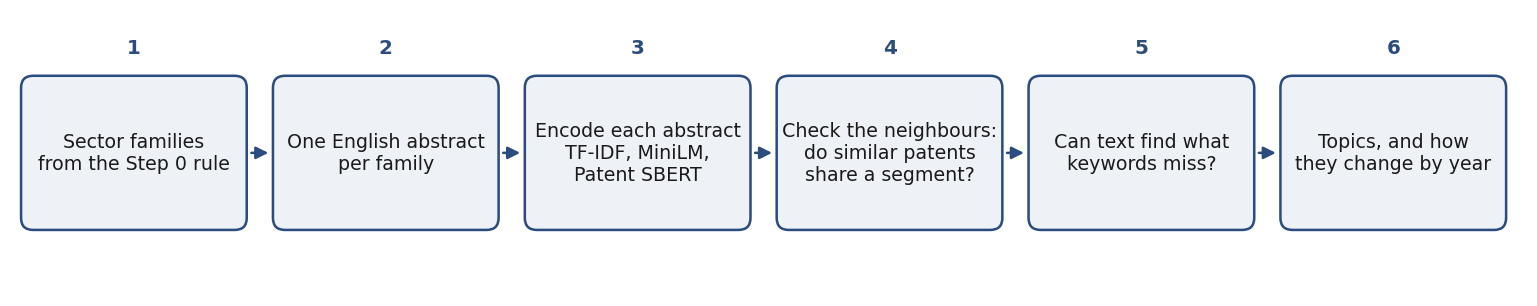

## What the notebook does

The numbers match the sections below.

2. Corpus. We take the families found by the Step 0 rule and keep one English abstract for each. One family is one invention, so it should count once. The encoders were trained on English, and the rule searches English text. Each family gets the segment its CPC codes point to, if there is exactly one.

3 to 5. Encodings. Each method turns an abstract into a vector. TF-IDF counts words and gives more weight to the rare ones. GloVe averages word vectors (switched off). MiniLM is a general sentence model. Patent SBERT is the same kind of model, further trained on patents.

6. LLM. GPT-4.1 mini rewrites a sample of abstracts as function, solution and application. We then check, for each encoding, how many of a patent's closest patents share its segment. A good encoding puts patents of the same segment close together.

7. Can text find what keywords miss? Inside robot-code families, we look for humanoid patents with keywords, and with similarity to five known humanoid patents. We score both against the two humanoid CPC codes, which the text search never uses.

8. The whole sector. Every sector abstract is encoded with Patent SBERT and the vectors are saved for the next steps.

9. Topics. BERTopic groups the abstracts into topics, without us choosing how many. We count the patents of each topic per year to see which subfields grow (Step 2).

10. Text novelty. For every patent, we measure how different it is from the sector's earlier patents (Step 4).

11. LLM check of the Step 0 rule. The LLM labels 100 sector patents and 100 robot patents outside the sector, to help the hand labelling of Step 0.

## Before you run it

Run on TEST first, to check that the code works. TEST has too few humanoid abstracts for the numbers to mean anything. Use PROD once the Step 0 rule is frozen.

The Step 0 rule (which patents belong to the humanoid sector) is written in one file, `config/sector_rule.yaml`. It holds the CPC codes, the keywords, the exclusions, the years and the segments. Step 0, notebook 20 and this notebook all read that same file, so they all study exactly the same patents.

To change the rule, we edit that file only, then run Step 0 and notebooks 20 and 21 again. The list of families saved by Step 0 is not needed here: this notebook builds the sector itself from the rule, and only uses the list, if it finds it, to check that both give the same families.

The LLM step sends a sample of abstracts (`LLM_SAMPLE`) to OpenAI, exactly as the teacher's Tutorial 2 does, with the course key. Only those abstracts leave TIP. The course key is hard-coded in the variable `OPENAI_KEY` of the settings cell. It is a test key the teacher made for this course, with limits, so we keep it in the notebook on purpose. Every answer is saved in a file, so a second run calls nothing and costs nothing. Set `USE_LLM = False` to skip the step. TIP must be able to reach the internet: if it cannot, the notebook says so and carries on without the LLM.

GloVe is off because its download is about 130 MB and it helps little with patent text.

The abstracts and cached files stay in the outputs folder, which git ignores. They are PATSTAT data under licence, so they must not be committed or shared.

Send back the printed tables and any error message. No abstract is needed.

In [1]:
%pip install -q sentence-transformers langchain-openai langchain-core pydantic


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import sys
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
from sqlalchemy import func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import TLS201_APPLN, TLS202_APPLN_TITLE, TLS203_APPLN_ABSTR, TLS224_APPLN_CPC

In [3]:
ENV = 'PROD'                      # TEST to check that the code runs; PROD only for the final numbers
SEED = 34                         # fixes every random draw, so a rerun gives the same samples

# ---------------------------------------------------------------- the sector rule
# The rule (which patents are in the sector) is written once, in config/sector_rule.yaml.
# Step 0 and notebooks 20 and 21 all read it, so they study the same patents. To change the rule, edit that file only.
sys.path.insert(0, str(Path('src').resolve()))
from sector_rule import SectorQueries, load_rule, rule_constants

RULE = load_rule()
(CORE_CPC, ROBOT_CPC, EXCLUDE_CPC, PROSTHESIS_CPC, EXCLUDE_PROSTHESES, STRONG_KW, MEDIUM_KW,
 ADJACENT_KW, EXCLUDE_KW, TRUTH_CPC, QUERY_VERSION, YEAR_MIN, YEAR_MAX, IPR_TYPE) = rule_constants(RULE)
SEGMENTS = RULE['comparison_segments']   # the six draft segments of the comparison (section 2)

# ---------------------------------------------------------------- years
COMPLETE_MAX = YEAR_MAX - 3       # 2023-2025 are truncated (about 18-month publication lag): never read them as a decline

# ---------------------------------------------------------------- files (ignored by git: they stay on TIP)
TEXT_DIR = Path('outputs/t2_text')
TEXT_DIR.mkdir(parents=True, exist_ok=True)
STEP0_IDS = Path('outputs/step0/sector_family_ids.csv')
RUN_TAG = f"{ENV}_{QUERY_VERSION.replace(' ', '_')}"      # cached files carry the environment and the rule version

# ---------------------------------------------------------------- encodings (sections 2-6)
PER_SEGMENT = 300                 # families per segment in the comparison corpus (keeps the encodings fast on CPU)
FOCAL_FAMILY_ID = None            # a DOCDB family the team knows to be at the core of the sector; None = pick one by keyword
USE_GLOVE = False                 # downloads about 130 MB of GloVe vectors
USE_LLM = True                    # True: send samples of abstracts to OpenAI (sections 6 and 11, as in the teacher's tutorial). False: skip them
OPENAI_KEY = ''   # the course test key (teacher's tutorial, with limits): hard-coded on purpose
LLM_MODEL = 'gpt-4.1-mini'        # the model used in the tutorial; a small, cheap one is enough to summarise an abstract
LLM_SAMPLE = 600                  # abstracts sent to the LLM: the same number from each segment (about 100), because every call costs money
EXTRACTIONS_FILE = TEXT_DIR / f'llm_extractions_{RUN_TAG}_{LLM_SAMPLE}.jsonl'   # the LLM's answers are saved here, so nothing is paid for twice

# ---------------------------------------------------------------- text for Step 0 (section 7 and 11)
POOL_YEARS = range(2005, 2023)    # priority years of the pool of robot-code families
PER_YEAR = 200                    # families per year in the pool
RATER_SAMPLE = 100                # families of each group labelled by the LLM in section 11

# ---------------------------------------------------------------- topics and novelty (sections 9 and 10)
TOPIC_PER_YEAR = 150              # families per year used to build the topics (then every family gets a topic)
MIN_TOPIC_DOCS = 300              # BERTopic needs a few hundred abstracts; below this it is skipped
NOVELTY_WINDOW = 5                # years before (and after) a patent that we compare it with
NOVELTY_TOP_K = 10                # we average the similarity to the 10 closest patents of that window
SECTOR_WORDS = {'robot', 'robots', 'humanoid'}    # words every sector patent uses: not useful to describe topics
PATENT_STOP_WORDS = {
    'said', 'wherein', 'whereby', 'thereof', 'therein', 'comprising', 'comprises', 'comprise', 'including',
    'includes', 'plurality', 'least', 'configured', 'provided', 'providing', 'present', 'invention',
    'disclosed', 'disclosure', 'embodiment', 'embodiments', 'method', 'methods', 'device', 'devices',
    'apparatus', 'system', 'systems', 'unit', 'first', 'second', 'third', 'one', 'having', 'based',
}
pd.set_option('display.max_colwidth', 120)

In [4]:
patstat = PatstatClient(env=ENV)
db = patstat.orm()

In [5]:
# The sector as PATSTAT queries, built from the rule (src/sector_rule.py).
Q = SectorQueries(db, SimpleNamespace(APPLN=TLS201_APPLN, TITLE=TLS202_APPLN_TITLE,
                                      ABSTR=TLS203_APPLN_ABSTR, CPC=TLS224_APPLN_CPC), RULE)
cpc_families = Q.cpc_families
family_years = Q.family_years
sector_query = Q.sector_query
SECTOR = Q.sector_subquery()          # one column, fid: the sector's families, computed in the database


def scope(q):
    # keep only sector families; the join runs in the database, so no family IDs travel to Python
    return Q.scope(q, SECTOR)


def n_families(q):
    # The database counts; Python receives one number.
    counted = db.query(func.count().label('n')).select_from(q.subquery())
    return int(patstat.df(counted).iloc[0, 0])

In [6]:
sector_ids_db = patstat.df(sector_query()).fid.tolist()
print(f'sector families ({ENV}, {QUERY_VERSION}): {len(sector_ids_db)}')
if STEP0_IDS.exists():
    step0_ids = set(pd.read_csv(STEP0_IDS)['docdb_family_id'])
    print('same families as the Step 0 list:', step0_ids == set(sector_ids_db))
else:
    print('Step 0 list not found at', STEP0_IDS, '(fine: this notebook builds the sector from the same rule file)')

# Layer A (core code + strong word) is inside layer C (strong word), so the core code adds no family by itself.
# This number is what the core code alone would add: the team decides in Step 0 whether to take them.
core_outside = n_families(cpc_families(CORE_CPC).except_(sector_query()))
print(f'families with the core code {CORE_CPC} that are NOT in the sector: {core_outside:,}')

sector families (PROD, v0.2 draft): 8268
Step 0 list not found at outputs/step0/sector_family_ids.csv (fine: this notebook builds the sector from the same rule file)
families with the core code ['B62D57/032'] that are NOT in the sector: 3,576


**What the PROD run shows.** The sector has 8,268 families with the v0.2 rule. A day earlier it had 7,522 with the same rule, so TIP loaded new data in between: numbers from the two days are not directly comparable.

3,576 families have the walking-robot code (B62D 57/032) but are not in the sector, because they have no humanoid word. That is 43% more than the sector. Many are probably four-legged or other walking machines, so we should read a sample before deciding whether the code alone is enough.

## 2. The corpus: English abstracts of the sector

We take one English abstract per sector family. Then each family gets a segment, from its CPC codes, if it falls in exactly one of the six draft segments. Families with no segment or with several segments are kept for the topics and the novelty score, but left out of the comparison, because the comparison needs one clear label per patent.

The labels come from the examiners' codes, so they are not the truth. We use them to compare the encodings with each other.

In [7]:
def sector_abstracts():
    "One English abstract per sector family, with its priority year."
    fy = family_years(SECTOR)
    q = (db.query(fy.c.fid.label('docdb_family_id'), fy.c.year.label('year'), TLS201_APPLN.appln_id.label('appln_id'),
                  TLS203_APPLN_ABSTR.appln_abstract.label('abstract'))
         .select_from(fy)
         .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == fy.c.fid)
         .join(TLS203_APPLN_ABSTR, TLS203_APPLN_ABSTR.appln_id == TLS201_APPLN.appln_id)
         .filter(TLS203_APPLN_ABSTR.appln_abstract_lg == 'en', TLS201_APPLN.appln_id < 900000000))
    return patstat.df(q).sort_values('appln_id').drop_duplicates('docdb_family_id').reset_index(drop=True)


def segment_labels(family_ids):
    "Segment of each family if it has codes in exactly one segment, else NaN."
    member = {}
    for segment, prefixes in SEGMENTS.items():
        # only the sector's families come back, so the list stays small
        ids = set(patstat.df(scope(cpc_families(prefixes))).fid)
        for f in family_ids:
            if f in ids:
                member.setdefault(f, []).append(segment)
    return pd.Series({f: (member[f][0] if len(member.get(f, [])) == 1 else np.nan) for f in family_ids})


CORPUS_FILE = TEXT_DIR / f'corpus_{RUN_TAG}.csv'
if CORPUS_FILE.exists():
    sector_abs = pd.read_csv(CORPUS_FILE)
else:
    sector_abs = sector_abstracts()
    sector_abs['segment'] = sector_abs.docdb_family_id.map(segment_labels(sector_abs.docdb_family_id.tolist()))
    sector_abs.to_csv(CORPUS_FILE, index=False)

labelled = sector_abs.dropna(subset=['segment'])
# shuffle inside each segment, then keep the first PER_SEGMENT: a random sample of each segment
corpus = (labelled.groupby('segment').sample(frac=1, random_state=SEED)
          .groupby('segment').head(PER_SEGMENT).reset_index(drop=True))
texts = corpus['abstract'].tolist()
labels = corpus['segment'].to_numpy()
print(f'{len(sector_abs):,} sector families with an English abstract; {len(labelled):,} with exactly one segment; corpus {len(corpus):,}')
print(corpus.segment.value_counts().to_string())
if len(corpus) < 30 or corpus.segment.nunique() < 2:
    print('\nWARNING: the corpus is too small for a meaningful comparison. The numbers below only check that the code runs.')

7,427 sector families with an English abstract; 3,660 with exactly one segment; corpus 1,290
segment
Body hardware                 300
Locomotion and balance        300
Perception, AI and control    300
Manipulation and hands        300
Human-robot interaction        70
Safety and teleoperation       20


**What the PROD run shows.** 7,427 families have an English abstract, and 3,660 of them fall in exactly one segment. The corpus has 300 families for each of the four big segments, but only 70 for human-robot interaction and 20 for safety: these two are too small to judge well.

Careful: this list of abstracts was saved during the first run, on the older data (before TIP's update). That is why the last check of the notebook fails ("every corpus family is a sector family"). The next run has to rebuild it.

We also choose one focal patent, a patent we know is at the core of the sector. We then ask every encoding the same question: which patents are the most similar to this one? If the encodings give different answers, the choice of encoding matters. Set `FOCAL_FAMILY_ID` to a family the team has picked. By default, the first family with a strong humanoid word in its abstract is used.

In [8]:
if FOCAL_FAMILY_ID is not None and (corpus.docdb_family_id == FOCAL_FAMILY_ID).any():
    FOCAL = int(corpus.index[corpus.docdb_family_id == FOCAL_FAMILY_ID][0])
else:
    has_strong = corpus.abstract.str.lower().str.contains('|'.join(re.escape(k) for k in STRONG_KW))
    FOCAL = int(corpus.index[has_strong][0]) if has_strong.any() else 0
print('focal family:', int(corpus.loc[FOCAL, 'docdb_family_id']), '| segment:', corpus.loc[FOCAL, 'segment'])
print(corpus.loc[FOCAL, 'abstract'][:600])

focal family: 67925657 | segment: Body hardware
The invention discloses a waist joint mechanism and a robot and relates to the technical field of humanoid robots. The waist joint mechanism comprises a waist ball seat, a waist ball cap and a waist ball. A containing cavity is formed jointly by the waist ball seat and the waist ball cap. The inner sidewall of the containing cavity is provided with a first sunken part and a second sunken part which are symmetric. The waist ball is arranged in the containing cavity. The sidewall of the waist ball is provided with a first limiting protrusion and a second limiting protrusion which are symmetric. 


## 3. TF-IDF

TF-IDF turns an abstract into a list of word weights. A word gets a high weight when it is frequent in this abstract and rare in the others. We keep word pairs (*legged robot*), and we remove the legal words every patent uses (*said*, *wherein*, *plurality*).

It is simple, cheap and easy to explain. But it does not know synonyms: *biped* and *two-legged* are two unrelated words for it, and patents written in the same legal style can look alike even when the inventions differ.

In [9]:
tfidf = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | PATENT_STOP_WORDS), ngram_range=(1, 2),
                        min_df=2, max_df=0.5, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(texts)
print(f'{X_tfidf.shape[0]} abstracts x {X_tfidf.shape[1]:,} terms; {X_tfidf.nnz / max(X_tfidf.shape[0], 1):.0f} non-zero terms per abstract')


def top_terms(row, k=10):
    "The k terms with the highest TF-IDF weight in one document."
    weights = X_tfidf[row].toarray().ravel()
    best = weights.argsort()[::-1][:k]
    return pd.Series(weights[best], index=tfidf.get_feature_names_out()[best]).round(3)


def most_similar(X, row, k=5):
    "The k documents most similar to document `row` (cosine), without the document itself."
    sims = cosine_similarity(X[row:row + 1], X).ravel()
    sims[row] = -np.inf
    best = sims.argsort()[::-1][:min(k, len(sims) - 1)]
    return pd.DataFrame({'similarity': sims[best].round(3), 'segment': labels[best],
                         'abstract': [texts[i][:140] + '...' for i in best]}, index=best)


display(top_terms(FOCAL).to_frame('weight'))
display(most_similar(X_tfidf, FOCAL))

1290 abstracts x 13,521 terms; 75 non-zero terms per abstract


,weight
sunken,0.279
limiting protrusion,0.248
waist,0.229
protrusion,0.222
end face,0.208
waist joint,0.199
ball,0.194
containing cavity,0.179
joint mechanism,0.178
gaps,0.167


,similarity,segment,abstract
14,0.157,Body hardware,The invention provides a machine vision gait planning robot. The machine vision gait planning robot comprises a driv...
39,0.146,Body hardware,"The invention provides a waist transmission mechanism and a humanoid robot, the waist transmission mechanism compris..."
459,0.129,Locomotion and balance,"A foot assembly, a lower limb assembly and a humanoid robot, the foot assembly is applied to the humanoid robot, the..."
155,0.123,Body hardware,"The invention relates to the technical field of robots, and discloses an assembly structure of a waist omni-directio..."
777,0.114,Manipulation and hands,The invention belongs to the technical field of robot hands and discloses a parallel connection type parallel-clampi...


## 4. Word vectors (GloVe), switched off

GloVe gives each word a vector learned from Wikipedia and news, and an abstract becomes the average of its words. It knows synonyms, but it was not trained on patents, so many technical words are unknown to it. It is off (`USE_GLOVE`), as it adds little for patent text.

In [10]:
X_glove = None
if USE_GLOVE:
    %pip install -q gensim
    import gensim.downloader as gensim_api
    word_vectors = gensim_api.load('glove-wiki-gigaword-100')

    def tokens(text):
        words = re.findall(r'[a-z][a-z\-]+', text.lower())
        return [w for w in words if w not in ENGLISH_STOP_WORDS and w not in PATENT_STOP_WORDS]

    def average_embedding(text):
        known = [w for w in tokens(text) if w in word_vectors]
        return np.mean([word_vectors[w] for w in known], axis=0) if known else np.zeros(word_vectors.vector_size)

    X_glove = np.vstack([average_embedding(t) for t in texts])
    unknown = pd.Series([w for t in texts for w in tokens(t) if w not in word_vectors]).value_counts()
    print('technical words GloVe does not know (they vanish from the average):')
    display(unknown.head(15))
    display(most_similar(X_glove, FOCAL))
else:
    print('USE_GLOVE is False: skipped.')

USE_GLOVE is False: skipped.


## 5. Sentence models: general (MiniLM) and patent-trained (Patent SBERT)

These models read the whole sentence, so a word means different things in different contexts (*hand* in *robot hand* and in *second hand*). MiniLM was trained on web text and reads up to 256 tokens. Patent SBERT (Ascione & Sterzi, 2024) is the same model trained further on patents, and reads up to 512 tokens. Comparing the two shows what training on patent language adds.

A text longer than the limit is cut, so the cell prints how many abstracts are cut for each model.

In [11]:
from sentence_transformers import SentenceTransformer

minilm = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
patent_sbert = SentenceTransformer('graziasveva93/sbert-adapt-ub')
X_minilm = minilm.encode(texts, batch_size=64, show_progress_bar=False, normalize_embeddings=True)
X_patent = patent_sbert.encode(texts, batch_size=64, show_progress_bar=False, normalize_embeddings=True)


def share_truncated(model):
    "Share of abstracts longer than the maximum length of the model, and the median length in tokens."
    n_tokens = np.array([len(model.tokenizer(t)['input_ids']) for t in texts])
    return (n_tokens > model.max_seq_length).mean(), np.median(n_tokens)


for name, model in (('MiniLM', minilm), ('Patent SBERT-adapt-ub', patent_sbert)):
    share, median_tokens = share_truncated(model)
    print(f'{name}: maximum {model.max_seq_length} tokens; median abstract {median_tokens:.0f} tokens; cut: {share:.1%}')
print('\nMiniLM, most similar to the focal patent:')
display(most_similar(X_minilm, FOCAL))
print('Patent SBERT-adapt-ub:')
display(most_similar(X_patent, FOCAL))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (273 > 256). Running this sequence through the model will result in indexing errors


MiniLM: maximum 256 tokens; median abstract 218 tokens; cut: 22.0%
Patent SBERT-adapt-ub: maximum 512 tokens; median abstract 218 tokens; cut: 0.0%

MiniLM, most similar to the focal patent:


,similarity,segment,abstract
39,0.752,Body hardware,"The invention provides a waist transmission mechanism and a humanoid robot, the waist transmission mechanism compris..."
100,0.737,Body hardware,"The invention relates to the technical field of robot waist rotation, in particular to a robot waist rotation base w..."
129,0.734,Body hardware,"The invention relates to the field of robots, in particular to a waist joint for a humanoid robot. According to the ..."
155,0.733,Body hardware,"The invention relates to the technical field of robots, and discloses an assembly structure of a waist omni-directio..."
373,0.720,Locomotion and balance,"The crotch assembly is used for the humanoid robot and comprises a sacral joint mechanism and a hip joint mechanism,..."


Patent SBERT-adapt-ub:


,similarity,segment,abstract
155,0.953,Body hardware,"The invention relates to the technical field of robots, and discloses an assembly structure of a waist omni-directio..."
557,0.945,Locomotion and balance,"The invention relates to a mechanical leg and a biped robot. The mechanical leg comprises a hip joint part, a thigh ..."
100,0.944,Body hardware,"The invention relates to the technical field of robot waist rotation, in particular to a robot waist rotation base w..."
317,0.942,Human-robot interaction,"The invention discloses a detachable humanoid robot. The detachable humanoid robot comprises a head assembly, arm as..."
227,0.942,Body hardware,"The invention relates to the technical field of robots, and discloses a neck structure and a humanoid robot, and the..."


**What the PROD run shows.** MiniLM cuts 22% of the abstracts, because they are longer than the 256 tokens it can read. Patent SBERT cuts none, since it reads 512.

For the focal patent (a waist joint of a humanoid robot), both models find other waist, hip, neck and leg joints of humanoid robots, so they understand the topic. TF-IDF matched on words like "protrusion" and "cavity" and found less related patents.

## 6. LLM as extractor: rewrite each abstract in plain words

A patent abstract is written to be as broad and as legal as possible, so two patents about the same idea can look very different. An LLM can read an abstract like an analyst and write it again as three short fields:

- **function**: what the invention does, as a verb and an object (for example *keep balance*);
- **solution**: how it does it;
- **application**: where it can be used.

This follows Ascione & Tamagnone (2025), as in the teacher's Tutorial 2. We then encode these three short sentences with Patent SBERT and mix them with the encoding of the abstract. The mix is called a **hybrid** encoding.

**Why it matters for the project.** If the plain version groups patents better than the raw abstract, we have a better way to find humanoid patents that carry no CPC code or use unusual words. Section 6.1 tests this.

**Two limits.** Every patent needs one paid call, so we only use a sample. And an LLM can invent details, so we read a few answers by hand before trusting it.

In [12]:
# The LLM service needs a key, like a password: the course test key from the teacher's tutorial.
# It is hard-coded in OPENAI_KEY, in the settings cell, on purpose: it is a test key made for this course, with limits.
os.environ['OPENAI_API_KEY'] = OPENAI_KEY


In [13]:
extractions = None

if USE_LLM:
    from concurrent.futures import ThreadPoolExecutor

    from langchain_core.prompts import ChatPromptTemplate
    from langchain_openai import ChatOpenAI
    from pydantic import BaseModel, Field

    def run_llm(chain, items, cache_file):
        """Send (docdb_family_id, text) pairs to the LLM, 5 at a time, and save the answers in cache_file.
        One trial call first: a wrong key or no internet then stops us after one call and not after hundreds."""
        errors = []

        def ask(item):
            family, text = item
            try:
                return {'docdb_family_id': int(family), **chain.invoke({'text': text}).model_dump()}
            except Exception as error:
                errors.append(f'{type(error).__name__}: {str(error)[:200]}')
                return None

        first = ask(items[0])
        if first is None:
            print('The first call failed, so nothing else was sent. Error:', errors[0])
            return None
        with ThreadPoolExecutor(max_workers=5) as workers:      # 5 calls at the same time, to save waiting
            answers = [first] + list(workers.map(ask, items[1:]))
        answers = [a for a in answers if a is not None]
        if errors:
            print(f'{len(errors)} of {len(items)} calls failed (first error: {errors[0]}).')
            print(f'The others are saved. To try the failed ones again, delete {cache_file.name} and run the cell again.')
        result = pd.DataFrame(answers)
        result.to_json(cache_file, orient='records', lines=True)    # the file stays on TIP (outputs/ is ignored by git)
        print(f'{len(result)} answers saved in {cache_file.name}.')
        return result

    # 1. The instruction we give the LLM. It is the teacher's text, so our results can be compared with the tutorial.
    prompt = ChatPromptTemplate.from_template("""
You are an expert analyst specializing in patents and scientific literature.
Your task is to read technical texts and distill their core technological concepts into clear, concise sentences.
You excel at identifying the main purpose of an invention (Function), explaining how it works (Solution),
and stating where it can be applied (Application).

Text:
{text}
""")

    # 2. The shape of the answer we ask for: three short texts. A fixed shape makes the answers easy to store and to compare.
    class Extraction(BaseModel):
        function: str = Field(default='', description="The main purpose, as 'verb + object' (e.g. 'keep balance'). What, not how.")
        solution: str = Field(default='', description='The technical means that achieve the function: how.')
        application: str = Field(default='', description='The settings where the solution can be used.')

    # 3. Which abstracts we send: the same number from each segment, so no segment is missing from the test.
    sample = corpus.groupby('segment').head(max(LLM_SAMPLE // max(corpus.segment.nunique(), 1), 1))

    if EXTRACTIONS_FILE.exists():
        # Answers saved by an earlier run: read them, call nothing.
        extractions = pd.read_json(EXTRACTIONS_FILE, lines=True)
        print(f'{len(extractions)} saved LLM answers read from {EXTRACTIONS_FILE.name}: nothing was sent.')
    elif os.environ.get('OPENAI_API_KEY'):
        # temperature 0 asks the model to be as repeatable as possible. Same input, (almost) same answer.
        chain = prompt | ChatOpenAI(model=LLM_MODEL, temperature=0).with_structured_output(Extraction, method='function_calling')
        extractions = run_llm(chain, list(zip(sample.docdb_family_id, sample.abstract)), EXTRACTIONS_FILE)
    else:
        print('No key given: the LLM step is skipped. The rest of the notebook does not need it.')
else:
    print('USE_LLM is False: skipped.')

if extractions is not None and len(extractions):
    # The answers are stored by family, so they stay right even if the corpus sample changes.
    row_of = pd.Series(corpus.index, index=corpus.docdb_family_id)
    extractions['row'] = extractions['docdb_family_id'].map(row_of)
    extractions = extractions.dropna(subset=['row']).astype({'row': int}).reset_index(drop=True)
    # Look at a few answers by hand. An LLM can invent things, and this is the quickest check that the answers make sense.
    examples = extractions.head(3)[['function', 'solution', 'application']].copy()
    examples.insert(0, 'abstract', [texts[r][:250] + '...' for r in extractions.head(3)['row']])
    display(examples)

The first call failed, so nothing else was sent. Error: OpenAIAuthenticationError: Error code: 401 - Incorrect API key provided: sk-proj-**************************************************************************************************************************************************


**What the PROD run shows.** Nothing: the first call was refused ("401 Incorrect API key"). The course key no longer works, so no abstract was rewritten and section 6 has no LLM results. The rest of the notebook does not need them.

## 6.1 Do the nearest neighbours belong to the same segment?

For each abstract, the share of its `k` nearest neighbours that carry the same segment label. The label is imperfect, so read the **ranking** of the encodings and not the level.

The second table repeats the check for the LLM sample only, with three versions of the same patents: the raw abstract, the LLM's short summary alone, and the two mixed (hybrid). If the hybrid beats the raw abstract, the LLM adds something. If it does not, it is not worth the cost for our project. The sample is smaller than the corpus, so compare these three rows with each other and not with the first table.

In [14]:
def neighbour_agreement(X, y, k=10):
    "Average share of the k nearest neighbours (cosine) that have the same label as the document."
    k = min(k, len(y) - 1)
    sims = cosine_similarity(X)
    np.fill_diagonal(sims, -np.inf)
    nearest = np.argsort(-sims, axis=1)[:, :k]
    return (y[nearest] == y[:, None]).mean()


ENCODINGS = {'TF-IDF': X_tfidf, 'MiniLM (general)': X_minilm, 'Patent SBERT-adapt-ub': X_patent}
if X_glove is not None:
    ENCODINGS['GloVe (average)'] = X_glove

agreement = pd.Series({name: neighbour_agreement(X, labels, k=10) for name, X in ENCODINGS.items()},
                      name='share of the 10 nearest neighbours in the same segment')
chance = float((corpus.segment.value_counts(normalize=True) ** 2).sum())
agreement.loc['(chance: random neighbours)'] = chance
agreement.round(3).to_frame().to_csv(TEXT_DIR / f'encoding_agreement_{RUN_TAG}.csv')
display(agreement.round(3).to_frame())

# The same check, for the sample the LLM rewrote.
if extractions is not None and len(extractions):
    rows = extractions['row'].to_numpy()
    fields = extractions[['function', 'solution', 'application']].fillna('')
    # the three short fields become one short text, which Patent SBERT turns into a vector like any abstract
    concepts = (fields['function'] + '. ' + fields['solution'] + '. ' + fields['application']).tolist()
    X_concepts = patent_sbert.encode(concepts, normalize_embeddings=True)
    X_hybrid = normalize(X_patent[rows] + X_concepts)       # hybrid: the two vectors added, then rescaled to length 1
    y_sample = labels[rows]
    print(f'LLM sample: {len(rows)} abstracts')
    display(pd.Series({'abstract (Patent SBERT)': neighbour_agreement(X_patent[rows], y_sample, k=5),
                       'LLM concepts (Patent SBERT)': neighbour_agreement(X_concepts, y_sample, k=5),
                       'hybrid': neighbour_agreement(X_hybrid, y_sample, k=5)},
                      name='share of the 5 nearest neighbours in the same segment').round(3).to_frame())

,share of the 10 nearest neighbours in the same segment
TF-IDF,0.593
MiniLM (general),0.663
Patent SBERT-adapt-ub,0.612
(chance: random neighbours),0.220


**What the PROD run shows.** For each abstract, we look at its 10 closest abstracts:

| Encoding | Share in the same segment |
|---|---|
| TF-IDF | 0.59 |
| MiniLM | 0.66 |
| Patent SBERT | 0.61 |
| random (chance) | 0.22 |

All three encodings are about three times better than chance, so the text does follow the segments. The general model MiniLM does a bit better than Patent SBERT here. The gap is small, and the segments come from CPC codes, not from a true answer, so it does not prove MiniLM is better for our project.

In [15]:
def confusion_of_neighbours(X, k=10):
    "Rows: segment of the patent; columns: share of its k nearest neighbours in each segment."
    k = min(k, len(labels) - 1)
    sims = cosine_similarity(X)
    np.fill_diagonal(sims, -np.inf)
    nearest = np.argsort(-sims, axis=1)[:, :k]
    pairs = pd.DataFrame({'patent': np.repeat(labels, k), 'neighbour': labels[nearest].ravel()})
    return pd.crosstab(pairs['patent'], pairs['neighbour'], normalize='index').round(2)


for name in ['TF-IDF', 'Patent SBERT-adapt-ub']:
    print(name)
    display(confusion_of_neighbours(ENCODINGS[name]))


def top_k(X, row, k=10):
    sims = cosine_similarity(X[row:row + 1], X).ravel()
    sims[row] = -np.inf
    return set(np.argsort(-sims)[:min(k, len(sims) - 1)])


tops = {name: top_k(X, FOCAL) for name, X in ENCODINGS.items()}
print('patents two encodings share among the 10 nearest neighbours of the focal patent:')
display(pd.DataFrame({a: {b: len(tops[a] & tops[b]) for b in tops} for a in tops}))

TF-IDF


neighbour,Body hardware,Human-robot interaction,Locomotion and balance,Manipulation and hands,"Perception, AI and control",Safety and teleoperation
patent,,,,,,
Body hardware,0.46,0.05,0.19,0.15,0.13,0.02
Human-robot interaction,0.24,0.32,0.11,0.06,0.26,0.01
Locomotion and balance,0.17,0.02,0.64,0.06,0.10,0.01
Manipulation and hands,0.12,0.01,0.05,0.74,0.06,0.01
"Perception, AI and control",0.14,0.06,0.09,0.08,0.62,0.01
Safety and teleoperation,0.27,0.06,0.18,0.20,0.27,0.03


Patent SBERT-adapt-ub


neighbour,Body hardware,Human-robot interaction,Locomotion and balance,Manipulation and hands,"Perception, AI and control",Safety and teleoperation
patent,,,,,,
Body hardware,0.45,0.03,0.23,0.12,0.15,0.02
Human-robot interaction,0.24,0.30,0.08,0.03,0.33,0.01
Locomotion and balance,0.18,0.01,0.70,0.02,0.09,0.01
Manipulation and hands,0.10,0.00,0.03,0.80,0.06,0.00
"Perception, AI and control",0.15,0.07,0.09,0.07,0.61,0.01
Safety and teleoperation,0.31,0.04,0.21,0.18,0.24,0.02


patents two encodings share among the 10 nearest neighbours of the focal patent:


,TF-IDF,MiniLM (general),Patent SBERT-adapt-ub
TF-IDF,10,3,2
MiniLM (general),3,10,5
Patent SBERT-adapt-ub,2,5,10


**What the PROD run shows.** The segments are not all equally clear in the text (Patent SBERT, share of neighbours in the same segment):

- Manipulation and hands (0.80) and locomotion (0.70) are well separated.
- Perception, AI and control (0.61) is fairly clear.
- Body hardware (0.45) mixes with locomotion, because legs and joints appear in both.
- Human-robot interaction (0.30) is spread over perception and body hardware.
- Safety and teleoperation (0.02) cannot be told apart at all.

For the next steps, we should merge safety into another segment, and probably human-robot interaction too.

The three encodings also disagree on the focal patent: TF-IDF shares only 2 or 3 of its 10 closest patents with the other two. So the choice of encoding changes which patents we find.

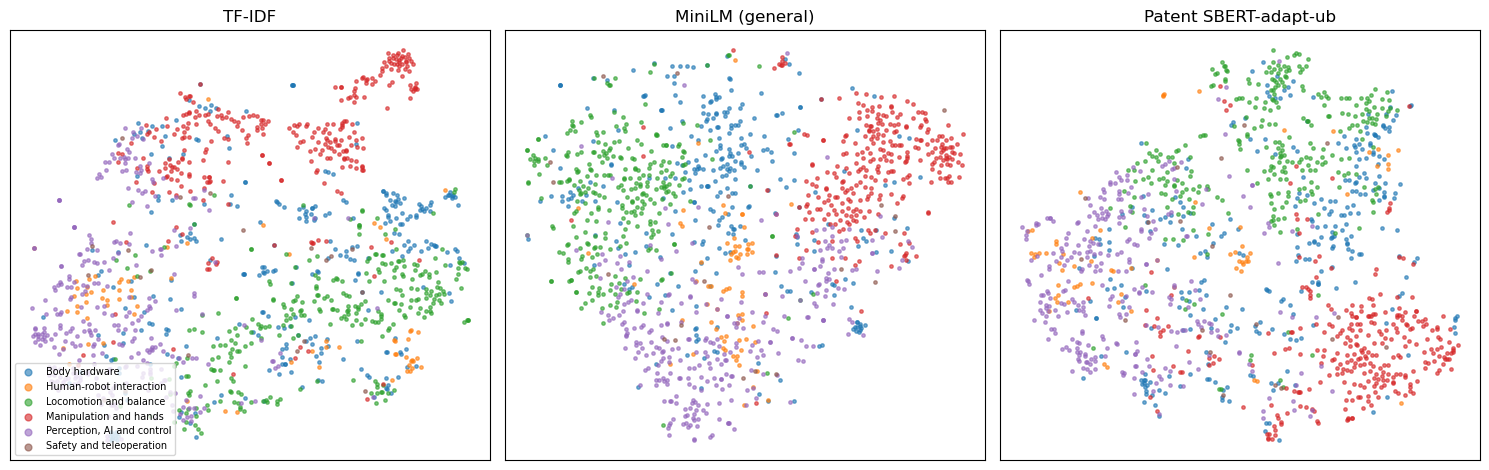

In [16]:
if len(corpus) >= 30:
    fig, axes = plt.subplots(1, len(ENCODINGS), figsize=(5 * len(ENCODINGS), 4.8))
    axes = np.atleast_1d(axes)
    palette = dict(zip(sorted(set(labels)), plt.cm.tab10.colors))
    for ax, (name, X) in zip(axes, ENCODINGS.items()):
        dense = TruncatedSVD(min(50, X.shape[1] - 1, X.shape[0] - 1), random_state=0).fit_transform(X) if name == 'TF-IDF' else X
        xy = TSNE(n_components=2, metric='cosine', init='pca', random_state=0,
                  perplexity=min(30, (len(labels) - 1) / 3)).fit_transform(dense)
        for segment, colour in palette.items():
            mask = labels == segment
            ax.scatter(xy[mask, 0], xy[mask, 1], s=6, alpha=0.6, color=colour, label=segment)
        ax.set(title=name, xticks=[], yticks=[])
    axes[0].legend(loc='lower left', fontsize=7, markerscale=2)
    plt.tight_layout()
    plt.savefig(TEXT_DIR / f'tsne_{RUN_TAG}.png', dpi=150)
    plt.show()
else:
    print('Corpus under 30 abstracts: no map.')

**What the PROD run shows.** In the three maps, hands (red) form their own clear group, and locomotion (green) and perception (purple) are mostly separate. Body hardware (blue) is scattered between them. This matches the table above: the text separates hands and walking well, and the other segments less.

## 7. Text for Step 0: can similarity find what the keywords miss?

This is the test closest to our real problem. We take patents with a robot code, and try to find the humanoid ones from their abstract alone, in two ways:

- A, keywords: the strong and medium words of our rule;
- B, similarity: the patents most similar to five known humanoid patents (the focal patents). B selects as many patents as A, so the two are compared fairly.

We then check the found patents against the two humanoid CPC codes (walking robots B62D 57/032 and human-like robots G06N 3/008), which neither search uses. The five focal patents are left out of the scoring, because B would always find them.

The codes are not the full truth. The walking code also covers four-legged robots, and examiners miss things. So the table compares the two ways, and the 100 hand-labelled patents of Step 0 give the real precision. The most useful output is the list of patents only the similarity finds: reading them suggests new keywords.

In [17]:
POOL_FILE = TEXT_DIR / f'pool_{RUN_TAG}.csv'
symbol = func.replace(TLS224_APPLN_CPC.cpc_class_symbol, ' ', '')


def pool_for_year(year):
    "English abstracts of robot-code families with this priority year, one per family."
    q = (db.query(TLS201_APPLN.docdb_family_id, TLS201_APPLN.appln_id, TLS203_APPLN_ABSTR.appln_abstract.label('abstract'))
         .select_from(TLS224_APPLN_CPC)
         .join(TLS201_APPLN, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
         .join(TLS203_APPLN_ABSTR, TLS203_APPLN_ABSTR.appln_id == TLS201_APPLN.appln_id)
         .filter(or_(*(symbol.like(p + '%') for p in ROBOT_CPC)), TLS203_APPLN_ABSTR.appln_abstract_lg == 'en',
                 TLS201_APPLN.earliest_filing_year == year, TLS201_APPLN.ipr_type == IPR_TYPE,
                 TLS201_APPLN.appln_id < 900000000)
         .distinct().limit(PER_YEAR * 3))
    df = patstat.df(q).drop_duplicates('docdb_family_id')
    return df.sample(min(len(df), PER_YEAR), random_state=SEED).assign(year=year)


def has_group(appln_ids, prefixes):
    "Set of the applications (among appln_ids) with a CPC symbol in one of the groups."
    q = (db.query(TLS224_APPLN_CPC.appln_id).filter(TLS224_APPLN_CPC.appln_id.in_(appln_ids))
         .filter(or_(*(symbol.like(p + '%') for p in prefixes))).distinct())
    return set(patstat.df(q)['appln_id'])


if POOL_FILE.exists():
    pool = pd.read_csv(POOL_FILE).drop_duplicates('docdb_family_id', ignore_index=True)
else:
    # a family can appear under two priority years: keep one row per family, across years too
    pool = pd.concat([pool_for_year(y) for y in POOL_YEARS], ignore_index=True)
    pool = pool.drop_duplicates('docdb_family_id', ignore_index=True)
    in_truth = has_group([int(i) for i in pool['appln_id']], TRUTH_CPC)
    pool['truth'] = pool['appln_id'].isin(in_truth)
    pool.to_csv(POOL_FILE, index=False)

pool['in_sector'] = pool['docdb_family_id'].isin(set(sector_ids_db))   # used in section 11
pool_texts = pool['abstract'].tolist()
truth = pool['truth'].to_numpy()
print(f'{len(pool):,} robot-code families, {truth.sum():,} of them with a code of {TRUTH_CPC}; {pool.in_sector.sum():,} in our sector')

3,597 robot-code families, 179 of them with a code of ['B62D57/032', 'G06N3/008']; 169 in our sector


In [18]:
KEYWORDS = STRONG_KW + MEDIUM_KW
pattern = '|'.join(re.escape(k) for k in KEYWORDS)
by_keywords = pool['abstract'].str.lower().str.contains(pattern).to_numpy()

rng = np.random.default_rng(1)
positives = np.flatnonzero(truth)
FOCAL_ROWS = rng.choice(positives, size=min(5, len(positives)), replace=False) if len(positives) else np.array([], dtype=int)
scored = np.ones(len(pool), dtype=bool)
scored[FOCAL_ROWS] = False          # the focal patents are the starting point, so they are not scored
print(f'{len(FOCAL_ROWS)} focal families (true ones, drawn at random: in the project, pick them by hand)')
print(f'Query A (keywords) selects {(by_keywords & scored).sum():,} families')

if len(FOCAL_ROWS) and len(pool) > 5:
    pool_tfidf = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | PATENT_STOP_WORDS), ngram_range=(1, 2),
                                 min_df=2, max_df=0.5, sublinear_tf=True).fit_transform(pool_texts)
    pool_patent = patent_sbert.encode(pool_texts, batch_size=64, show_progress_bar=False, normalize_embeddings=True)

    def focal_score(X):
        "Highest cosine similarity of each patent to the focal patents; the focal patents themselves can not be picked."
        score = np.asarray(cosine_similarity(X, X[FOCAL_ROWS])).max(axis=1)
        score[~scored] = -np.inf
        return score

    def top_n(score, n):
        selected = np.zeros(len(score), dtype=bool)
        selected[np.argsort(-score)[:n]] = True
        return selected

    n_selected = max(int((by_keywords & scored).sum()), 1)
    scores = {'TF-IDF': focal_score(pool_tfidf), 'Patent SBERT-adapt-ub': focal_score(pool_patent)}
    by_tfidf, by_sbert = top_n(scores['TF-IDF'], n_selected), top_n(scores['Patent SBERT-adapt-ub'], n_selected)

    def evaluate_query(selected):
        selected, true = selected & scored, truth & scored
        tp = (selected & true).sum()
        precision = tp / selected.sum() if selected.sum() else 0.0
        recall = tp / true.sum() if true.sum() else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        return {'selected': int(selected.sum()), 'precision': precision, 'recall': recall, 'F1': f1}

    queries = {'A: keywords': by_keywords, 'B: focal similarity, TF-IDF': by_tfidf,
               'B: focal similarity, Patent SBERT': by_sbert, 'A or B (Patent SBERT)': by_keywords | by_sbert,
               'A and B (Patent SBERT)': by_keywords & by_sbert}
    results = pd.DataFrame({name: evaluate_query(sel) for name, sel in queries.items()}).T.round(3)
    base_rate = (truth & scored).sum() / scored.sum()
    print(f'share of true families in the pool (what a random pick would get): {base_rate:.3f}')
    results.to_csv(TEXT_DIR / f'step0_query_comparison_{RUN_TAG}.csv')
    display(results)

    only_semantic = by_sbert & ~by_keywords & scored
    print(f'\n{only_semantic.sum()} families found by similarity and not by keywords; '
          f'{(only_semantic & truth).sum()} of them have a code of {TRUTH_CPC}')
    pool.loc[only_semantic, ['docdb_family_id', 'year', 'truth', 'in_sector', 'abstract']].to_csv(TEXT_DIR / f'only_semantic_{RUN_TAG}.csv', index=False)
    print('saved with their abstracts under outputs/t2_text/ (stays on TIP): read them for new keywords.')
else:
    print('Not enough true families in the pool to run the comparison (expected on a very small TEST database).')

5 focal families (true ones, drawn at random: in the project, pick them by hand)
Query A (keywords) selects 149 families
share of true families in the pool (what a random pick would get): 0.048


,selected,precision,recall,F1
A: keywords,149.0,0.329,0.282,0.303
"B: focal similarity, TF-IDF",149.0,0.121,0.103,0.111
"B: focal similarity, Patent SBERT",149.0,0.356,0.305,0.328
A or B (Patent SBERT),259.0,0.286,0.425,0.342
A and B (Patent SBERT),39.0,0.718,0.161,0.263



110 families found by similarity and not by keywords; 25 of them have a code of ['B62D57/032', 'G06N3/008']
saved with their abstracts under outputs/t2_text/ (stays on TIP): read them for new keywords.


**What the PROD run shows.** Among 3,597 robot-code families, only 4.8% have one of the two humanoid codes, so a random pick would be right 4.8% of the time.

| Way of searching | Right (precision) | Found (recall) |
|---|---|---|
| keywords | 33% | 28% |
| similarity, TF-IDF | 12% | 10% |
| similarity, Patent SBERT | 36% | 31% |
| keywords or similarity | 29% | 43% |
| keywords and similarity | 72% | 16% |

Similarity with Patent SBERT works as well as our keywords, and TF-IDF does much worse. The two ways find different patents: together they find 43% of the humanoid ones, and the patents found by both are right 72% of the time. 110 families were found by similarity and not by keywords, and 25 of them carry a humanoid code: reading them can give us new keywords.

Two limits: the five starting patents were picked at random, and they are counted in the scores, which helps the similarity search a little.

## 8. The whole sector, encoded once

Until now we worked on samples. For the next steps we need every sector patent. Here we encode all the sector's English abstracts with Patent SBERT (a few minutes on TIP) and save the vectors. Sections 9 and 10 use them, and Steps 2 and 4 can read them again without computing anything.

We use Patent SBERT and not MiniLM, even though MiniLM scored a little higher in section 6.1. Patent SBERT does not cut any abstract, it was trained on patents, and it is the model the course recommends. The difference in 6.1 was small, and it was measured against CPC labels, not against the truth.

In [19]:
EMB_FILE = TEXT_DIR / f'sector_embeddings_{RUN_TAG}.npy'           # one row per family, in the order of EMB_INDEX
EMB_INDEX = TEXT_DIR / f'sector_embedding_index_{RUN_TAG}.csv'
same_families = EMB_INDEX.exists() and pd.read_csv(EMB_INDEX)['docdb_family_id'].tolist() == sector_abs['docdb_family_id'].tolist()
if EMB_FILE.exists() and same_families:
    X_all = np.load(EMB_FILE)
    print(f'vectors read from {EMB_FILE.name}: nothing recomputed')
else:
    X_all = patent_sbert.encode(sector_abs['abstract'].tolist(), batch_size=64, show_progress_bar=True,
                                normalize_embeddings=True).astype(np.float32)
    np.save(EMB_FILE, X_all)
    sector_abs[['docdb_family_id', 'year', 'segment']].to_csv(EMB_INDEX, index=False)
print(f'{X_all.shape[0]:,} sector families x {X_all.shape[1]} dimensions')

Batches:   0%|          | 0/117 [00:00<?, ?it/s]

7,427 sector families x 384 dimensions


## 9. Topics of the sector and how they grow: BERTopic

A topic is a group of patents with similar text. BERTopic finds the groups by itself, so we do not choose how many there are. Patents that fit no group go to topic -1. Each topic is described by its most typical words, and we name it ourselves after reading a few of its abstracts.

We build the topics on 150 patents per year, so that old and recent years count the same. Then we give a topic to every sector patent and count the patents of each topic per year. This answers the Step 2 question of which subfields grow and which fade, in words rather than in CPC codes.

To compare growth, we split the complete years into two five-year periods and compare the number of patents. A topic that grows faster than the whole sector is gaining weight. The last three years are incomplete (publication lag), so they are shown in grey and never used for growth.

In [20]:
%pip install -q bertopic


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [21]:
complete = sector_abs['year'].between(YEAR_MIN, COMPLETE_MAX)
# shuffle each year, then keep the first TOPIC_PER_YEAR: a random sample of each complete year
fit_rows = (sector_abs[complete].groupby('year').sample(frac=1, random_state=SEED)
            .groupby('year').head(TOPIC_PER_YEAR).index.to_numpy())
print(f'{len(fit_rows):,} sector abstracts used to build the topics (complete years only)')

topic_model = None
if len(fit_rows) >= MIN_TOPIC_DOCS:
    from bertopic import BERTopic
    from hdbscan import HDBSCAN
    from sklearn.feature_extraction.text import CountVectorizer
    from umap import UMAP

    topic_model = BERTopic(
        embedding_model=patent_sbert,
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=42),
        hdbscan_model=HDBSCAN(min_cluster_size=15, metric='euclidean', prediction_data=True),
        vectorizer_model=CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | PATENT_STOP_WORDS | SECTOR_WORDS), ngram_range=(1, 2)),
    )
    topic_model.fit(sector_abs.loc[fit_rows, 'abstract'].tolist(), embeddings=X_all[fit_rows])

    # every sector family gets the topic it is closest to (or -1)
    all_topics, _ = topic_model.transform(sector_abs['abstract'].tolist(), embeddings=X_all)
    names = topic_model.get_topic_info().set_index('Topic')['Name']
    sector_abs['topic'] = all_topics
    sector_abs['topic_name'] = sector_abs['topic'].map(names)
    sector_abs[['docdb_family_id', 'year', 'segment', 'topic', 'topic_name']].to_csv(TEXT_DIR / f'family_topics_{RUN_TAG}.csv', index=False)

    info = topic_model.get_topic_info()[['Topic', 'Name', 'Representation']]
    info.insert(1, 'families (whole sector)', info['Topic'].map(sector_abs['topic'].value_counts()).fillna(0).astype(int))
    info.to_csv(TEXT_DIR / f'topics_{RUN_TAG}.csv', index=False)
    display(info)

    # Two typical abstracts per topic, cut short: enough to name the topic and to spot topics that are not humanoid robots.
    print('Two typical abstracts per topic (first 110 characters):')
    for t in info['Topic']:
        if t != -1:
            print(f'\n{names[t]}')
            for doc in topic_model.get_representative_docs(t)[:2]:
                print('   -', doc[:110])
else:
    print(f'Fewer than {MIN_TOPIC_DOCS} abstracts: BERTopic is skipped. Run this section on PROD.')

2,825 sector abstracts used to build the topics (complete years only)


,Topic,families (whole sector),Name,Representation
0,-1,2810,-1_control_walking_leg_body,"[control, walking, leg, body, foot, joint, motion, module, according, biped]"
1,0,2204,0_finger_hand_joint_object,"[finger, hand, joint, object, fingers, base, driving, shaft, mechanism, transmission]"
2,1,245,1_walking_leg_foot_legs,"[walking, leg, foot, legs, body, left, right, lower, connected, joint]"
3,2,204,2_voice_user_module_information,"[voice, user, module, information, service, sound, control, recognition, data, signal]"
4,3,331,3_control_motion_arm_module,"[control, motion, arm, module, controller, time, computer, according, data, model]"
5,4,235,4_head_neck_mechanism_joint,"[head, neck, mechanism, joint, arm, connected, driving, structure, motor, mouth]"
6,5,264,5_calibration_camera_coordinate_hand,"[calibration, camera, coordinate, hand, object, image, position, light, hand eye, target]"
7,6,137,6_leg_end_steering_joint,"[leg, end, steering, joint, mechanism, connecting, connected, biped, upper, rotation]"
8,7,163,7_ankle_bone_foot_toe,"[ankle, bone, foot, toe, metatarsal, joint, plate, metatarsal bone, mechanical, ankle joint]"
9,8,69,8_walking_control_biped_leg,"[walking, control, biped, leg, calculating, biped walking, foot, force, ground, road surface]"


Two typical abstracts per topic (first 110 characters):

0_finger_hand_joint_object
   - The invention discloses an inclined rod double-sliding-block linear horizontal-clamping indirect self-adaptive
   - Belonging to the technical field of anthropomorphic robots, a transitional underactuated robot finger device w

1_walking_leg_foot_legs
   - <P>PROBLEM TO BE SOLVED: To provide a bipedal walking robot which essentially avoids a problem of a ZMP, carri
   - <P>PROBLEM TO BE SOLVED: To provide a bipedal walking robot moved by telescopic motion of support legs, which 

2_voice_user_module_information
   - The invention discloses a voice interaction method based on a public display device and equipment, wherein the
   - The invention discloses an artificial intelligence interaction system suitable for banks and capable of improv

3_control_motion_arm_module
   - The invention discloses a control device and method for a humanoid robot. The control device comprises a robot
   - Provided is 

**What the PROD run shows.** BERTopic finds 21 topics. After giving a topic to every family:

- Hands and fingers is by far the largest topic, with 2,204 families (30%). Hands may weigh too much in our sector: many could be ordinary robot grippers.
- 2,810 families (38%) fit no topic.
- Most other topics are clear humanoid subjects: walking legs, ankles and feet, heads and necks, whole-body control, hand-eye calibration, voice interaction, gait learning.

Some topics are not humanoid robots and show holes in our rule:

- walking toys and pet robots (81 families);
- traditional Chinese medicine and massage (88), with for example a medicine granule;
- a bionic cattle and a four-legged lizard (35).

These three are about 3% of the sector. A few more are only partly humanoid: two-wheeled self-balancing vehicles, code-scanning and docking robots, roof monitoring, and depth-map animation software. We should add exclusion words for them in the Step 0 rule.

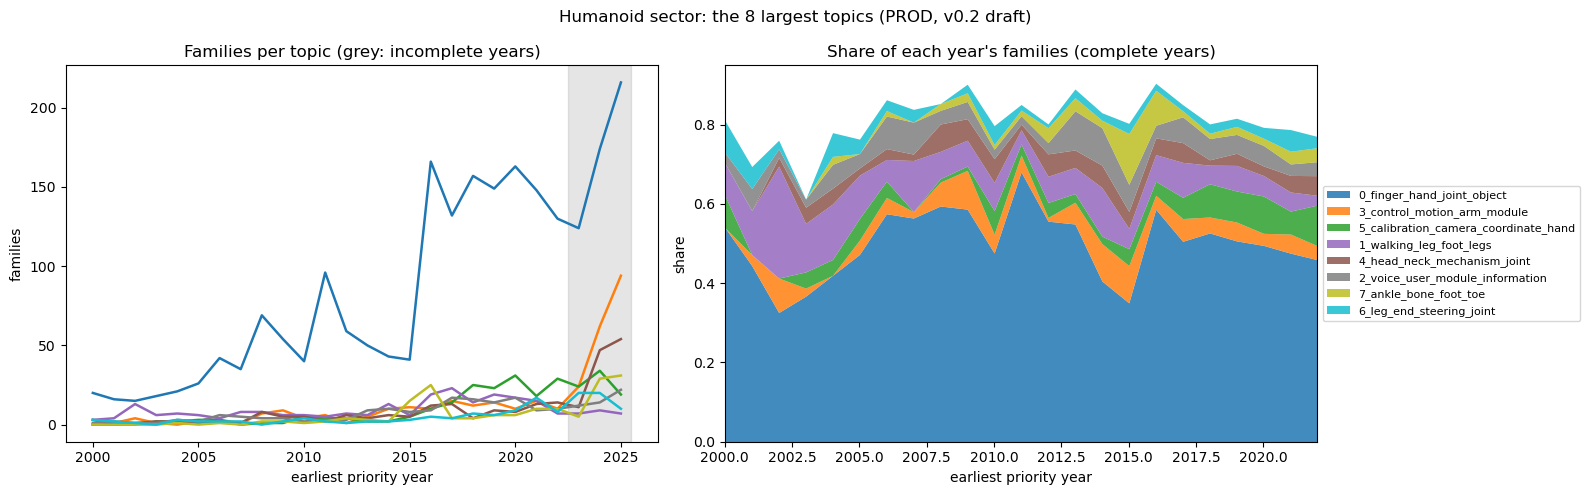

whole sector: 1,279 families in 2013-2017, 2,433 in 2018-2022 (growth x1.90)


,families 2013-2017,families 2018-2022,growth (late / early),"share of the sector, early","share of the sector, late",grows faster than the sector
topic_name,,,,,,
0_finger_hand_joint_object,432,747,1.73,0.338,0.307,False
5_calibration_camera_coordinate_hand,33,126,3.82,0.026,0.052,True
1_walking_leg_foot_legs,67,72,1.07,0.052,0.030,False
2_voice_user_module_information,53,66,1.25,0.041,0.027,False
3_control_motion_arm_module,51,61,1.20,0.040,0.025,False
4_head_neck_mechanism_joint,40,48,1.20,0.031,0.020,False
6_leg_end_steering_joint,16,47,2.94,0.013,0.019,True
10_legged_control_motion_branch chain,9,43,4.78,0.007,0.018,True
12_image_character_animation_depth,10,40,4.00,0.008,0.016,True


topics against the CPC segments (rows: topic, columns: segment; families):


segment,Body hardware,Human-robot interaction,Locomotion and balance,Manipulation and hands,"Perception, AI and control",Safety and teleoperation
topic_name,,,,,,
0_finger_hand_joint_object,208,3,42,994,55,8
10_legged_control_motion_branch chain,3,0,32,0,5,0
11_toy_dog_body_walking,1,0,7,3,2,1
12_image_character_animation_depth,1,0,1,0,37,0
13_wheel_balance_driving_leg,3,0,67,2,0,0
14_muscle_patient_medicine_pain,4,2,0,2,2,0
15_gait_learning_model_network,2,0,7,0,19,0
16_position_code_biped_data,5,0,7,0,13,0
17_walking_control_gait_period,0,0,11,0,4,0


In [22]:
if topic_model is not None:
    in_topics = sector_abs[sector_abs['topic'] != -1]
    counts = pd.crosstab(in_topics['year'], in_topics['topic_name'])        # families per topic and priority year, whole sector
    counts.to_csv(TEXT_DIR / f'topic_counts_by_year_{RUN_TAG}.csv')
    largest = in_topics['topic_name'].value_counts().index[:8]

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    counts[largest].plot(ax=axes[0], cmap='tab10', linewidth=1.8, legend=False)
    axes[0].axvspan(COMPLETE_MAX + 0.5, YEAR_MAX + 0.5, color='grey', alpha=0.2)
    axes[0].set(title='Families per topic (grey: incomplete years)', xlabel='earliest priority year', ylabel='families')
    share = counts.div(counts.sum(axis=1), axis=0).loc[:COMPLETE_MAX, largest]
    share.plot.area(ax=axes[1], cmap='tab10', alpha=0.85, linewidth=0)
    axes[1].set(title='Share of each year\'s families (complete years)', xlabel='earliest priority year', ylabel='share',
                xlim=(share.index.min(), share.index.max()))
    axes[1].legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8)
    fig.suptitle(f'Humanoid sector: the 8 largest topics ({ENV}, {QUERY_VERSION})')
    plt.tight_layout()
    plt.savefig(TEXT_DIR / f'topic_evolution_{RUN_TAG}.png', dpi=150)
    plt.show()

    # Growth: the last five complete years against the five before.
    late = list(range(COMPLETE_MAX - 4, COMPLETE_MAX + 1))
    early = list(range(COMPLETE_MAX - 9, COMPLETE_MAX - 4))
    per_year_total = sector_abs.groupby('year').size()
    sector_growth = per_year_total.reindex(late).sum() / per_year_total.reindex(early).sum()
    early_n = counts.reindex(early).fillna(0).sum()
    late_n = counts.reindex(late).fillna(0).sum()
    growth = pd.DataFrame({
        f'families {early[0]}-{early[-1]}': early_n.astype(int),
        f'families {late[0]}-{late[-1]}': late_n.astype(int),
        'growth (late / early)': (late_n / early_n.where(early_n > 0)).round(2),
        'share of the sector, early': (early_n / per_year_total.reindex(early).sum()).round(3),
        'share of the sector, late': (late_n / per_year_total.reindex(late).sum()).round(3),
    })
    growth['grows faster than the sector'] = growth['growth (late / early)'] > sector_growth
    growth = growth.sort_values(f'families {late[0]}-{late[-1]}', ascending=False)
    growth.to_csv(TEXT_DIR / f'topic_growth_{RUN_TAG}.csv')
    print(f'whole sector: {per_year_total.reindex(early).sum():,} families in {early[0]}-{early[-1]}, '
          f'{per_year_total.reindex(late).sum():,} in {late[0]}-{late[-1]} (growth x{sector_growth:.2f})')
    display(growth)

    labelled_topics = in_topics.dropna(subset=['segment'])
    print('topics against the CPC segments (rows: topic, columns: segment; families):')
    display(pd.crosstab(labelled_topics['topic_name'], labelled_topics['segment']))

**What the PROD run shows.** The sector almost doubled: 1,279 families in 2013-2017, 2,433 in 2018-2022 (x1.9).

| Grows faster than the sector | Grows slower, or shrinks |
|---|---|
| hand-eye calibration (33 to 126, x3.8) | hands and fingers (x1.7, its share drops from 34% to 31%) |
| wheel-legged robots (x4.1) | basic walking legs (x1.1) |
| legged motion control (x4.8) | heads and necks, voice interaction, control modules (x1.2) |
| gait learning with neural networks (x2.7) | ankles and feet (x0.7: fewer patents) |
| images, depth and animation (x4.0) | |

So the sector moves from mechanical design (legs, feet, heads) toward control, learning and perception, and toward new forms such as robots with wheels and legs. In the left chart, hands and whole-body control rise sharply after 2022, even though these last years are still incomplete.

Limits: 38% of the families have no topic, and several topics have fewer than 50 families, so their growth rates are rough.

## 10. Text novelty of every patent (for Step 4)

The future score of Step 4 has to judge recent patents, which have no citations yet. One ingredient the course suggests is text novelty (Kelly et al., 2021; Arts, Hou & Gomez, 2021): a patent is new when its text is far from the patents filed before it.

For every sector patent we look at the patents of the five years before it and take the 10 most similar ones:
- **novelty** is 1 minus their average similarity: high means the patent does not look like earlier work;
- **forward similarity** is the same average with the patents of the five years after it: high means later patents look like it, so it may have opened a path. It only exists for patents whose five following years are complete.

Two cautions. We compare only with the sector's own patents, in English, so a patent can look new here and still have prior art outside the sector. And the sector grows, so recent patents have more earlier patents to look like: compare patents of the same year with each other. The file keeps a rank within the year for that.

To prove the score works (the course asks for this), we check on older patents whether the novel ones were followed more by later patents.

novelty computed for 7,077 families (priority years 2005-2025)


year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
families,89.000,98.000,93.000,150.000,136.000,134.000,179.000,147.000,128.000,174.000,...,385.000,403.000,478.000,479.000,535.000,485.000,456.000,532.000,859.00,948.000
median_novelty,0.114,0.112,0.094,0.072,0.073,0.071,0.094,0.082,0.098,0.086,...,0.079,0.089,0.093,0.083,0.079,0.069,0.076,0.067,0.06,0.056


median novelty by segment:


,novelty
segment,
Safety and teleoperation,0.099
Human-robot interaction,0.098
Body hardware,0.075
"Perception, AI and control",0.075
Manipulation and hands,0.066
Locomotion and balance,0.058



check on 2,305 families with a complete forward window:
  correlation (Spearman) between novelty and forward similarity: -0.954
  forward/backward ratio, 10% most novel of their year: 1.077 | the other 90%: 1.011
  a ratio above 1 means later patents look more like the patent than earlier ones did: it opened a path.


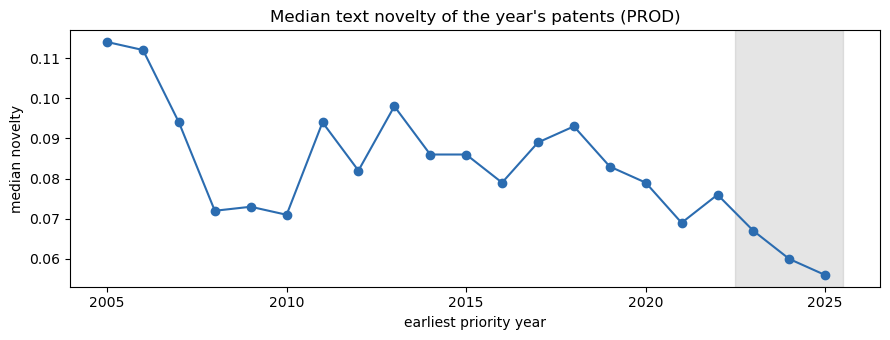

In [23]:
years = sector_abs['year'].to_numpy()
novelty = pd.DataFrame({'docdb_family_id': sector_abs['docdb_family_id'], 'year': years, 'segment': sector_abs['segment']})
for column in ('closest_prior_similarity', 'backward_similarity', 'forward_similarity'):
    novelty[column] = np.nan


def top_k_mean(rows, others, k=NOVELTY_TOP_K):
    "For each patent in rows: the highest similarity and the mean of the k highest similarities to the patents in others."
    sims = X_all[rows] @ X_all[others].T                 # the vectors have length 1, so this is the cosine similarity
    top = np.partition(sims, -k, axis=1)[:, -k:]
    return top.max(axis=1), top.mean(axis=1)


for year in np.unique(years):
    rows = np.flatnonzero(years == year)
    before = np.flatnonzero((years >= year - NOVELTY_WINDOW) & (years < year))
    after = np.flatnonzero((years > year) & (years <= year + NOVELTY_WINDOW))
    if year - NOVELTY_WINDOW >= YEAR_MIN and len(before) >= NOVELTY_TOP_K:          # a full window of earlier years
        novelty.loc[rows, 'closest_prior_similarity'], novelty.loc[rows, 'backward_similarity'] = top_k_mean(rows, before)
    if year + NOVELTY_WINDOW <= COMPLETE_MAX and len(after) >= NOVELTY_TOP_K:      # a full window of complete later years
        novelty.loc[rows, 'forward_similarity'] = top_k_mean(rows, after)[1]

novelty['novelty'] = 1 - novelty['backward_similarity']
novelty['novelty_rank_in_year'] = novelty.groupby('year')['novelty'].rank(pct=True).round(3)    # 1 = the most novel of its year
novelty['forward_vs_backward'] = (novelty['forward_similarity'] / novelty['backward_similarity']).round(3)
novelty.to_csv(TEXT_DIR / f'text_novelty_{RUN_TAG}.csv', index=False)

scored_years = novelty.dropna(subset=['novelty'])
print(f'novelty computed for {len(scored_years):,} families (priority years {int(scored_years.year.min()) if len(scored_years) else "-"}-{YEAR_MAX})')
by_year = scored_years.groupby('year').agg(families=('novelty', 'size'), median_novelty=('novelty', 'median')).round(3)
display(by_year.T)
print('median novelty by segment:')
display(scored_years.groupby('segment')['novelty'].median().round(3).sort_values(ascending=False).to_frame())

# Does it work? On patents whose five following years are complete: were the most novel ones followed more?
both = novelty.dropna(subset=['novelty', 'forward_similarity'])
if len(both) > 50:
    top_decile = both['novelty_rank_in_year'] >= 0.9
    print(f'\ncheck on {len(both):,} families with a complete forward window:')
    print(f'  correlation (Spearman) between novelty and forward similarity: {both["novelty"].corr(both["forward_similarity"], method="spearman"):.3f}')
    print(f'  forward/backward ratio, 10% most novel of their year: {both.loc[top_decile, "forward_vs_backward"].median():.3f} '
          f'| the other 90%: {both.loc[~top_decile, "forward_vs_backward"].median():.3f}')
    print('  a ratio above 1 means later patents look more like the patent than earlier ones did: it opened a path.')

if len(by_year):
    ax = by_year['median_novelty'].plot(figsize=(9, 3.5), marker='o', color='#2b6cb0')
    ax.axvspan(COMPLETE_MAX + 0.5, YEAR_MAX + 0.5, color='grey', alpha=0.2)
    ax.set(title=f'Median text novelty of the year\'s patents ({ENV})', xlabel='earliest priority year', ylabel='median novelty')
    plt.tight_layout()
    plt.savefig(TEXT_DIR / f'text_novelty_by_year_{RUN_TAG}.png', dpi=150)
    plt.show()

**What the PROD run shows.** The median novelty falls from 0.11 in 2005 to 0.06 in 2025. We should not read this as the sector becoming less inventive. The sector grows, so a recent patent is compared with many more earlier patents, and it is more likely to find close ones. The fall is at least partly caused by that.

The robot-human-interaction and safety patents look the most novel, and locomotion the least: walking is the oldest and most crowded subject.

The check printed at the end does not prove the score works. The strong negative correlation (-0.95) is expected by construction: a patent in a crowded area has close patents both before and after it. To prove the score, we still have to compare it with what happened later, such as citations and family size.

## 11. The LLM as a first reader for the Step 0 check

Step 0 asks us to check the sector rule by labelling about 100 random patents by hand. Here the LLM reads them first. It labels 100 random sector patents and 100 random robot patents that our rule left out, using our definition of a humanoid robot (Phase 1 notes). It also gives the main use (household, service, industrial...), which Step 0 asks us to tag.

Why it helps: the share of sector patents the LLM calls humanoid is a first estimate of the rule's precision, and the share of left-out patents it calls humanoid shows what the rule misses. The LLM is not the truth. It gives us a first label and a reason for every patent, so the hand labelling is faster and the disagreements show where to look. The labelling sheet is saved with an empty column for our own label.

In [24]:
RATER_FILE = TEXT_DIR / f'step0_llm_rater_{RUN_TAG}_{RATER_SAMPLE}.jsonl'
RATER_LABELS = ('humanoid robot', 'part or control of a humanoid robot', 'robot hand or arm, not tied to a humanoid',
                'other legged robot', 'not a humanoid robot', 'unclear')
ratings = None

# the two samples: random sector families, and random robot-code families the rule left out
rater_sample = pd.concat([
    sector_abs.sample(min(RATER_SAMPLE, len(sector_abs)), random_state=SEED).assign(group='in the sector'),
    pool[~pool['in_sector']].sample(min(RATER_SAMPLE, int((~pool['in_sector']).sum())), random_state=SEED).assign(group='robot code, outside the sector'),
])[['docdb_family_id', 'year', 'group', 'abstract']].reset_index(drop=True)

if USE_LLM:
    from typing import Literal

    # Our definition of the sector (brain/Phase 1 Humanoid Terms.md, section 1), written for the LLM.
    rater_prompt = ChatPromptTemplate.from_template("""
You classify patents for a study of the humanoid robot sector.
A humanoid robot is a robot with a human body plan: it walks on two legs, or it has a torso with two arms and a head
(a wheeled base with two arms and a head also counts).
NOT humanoid: four-legged or multi-legged robots, exoskeletons and prostheses, toys and dolls, crash-test dummies and
mannequins, software avatars without a robot, ordinary industrial robot arms.

Read the patent abstract and choose one label:
- humanoid robot: the invention is a humanoid robot as a whole;
- part or control of a humanoid robot: a component, a control method or software made for a humanoid or biped robot;
- robot hand or arm, not tied to a humanoid: a hand, gripper or arm that could be used on any robot;
- other legged robot: a walking robot that is not humanoid;
- not a humanoid robot: anything else;
- unclear: the abstract does not say enough.
Also give the main use of the invention and one short sentence explaining the label.

Patent abstract:
{text}
""")

    class Rating(BaseModel):
        label: Literal[RATER_LABELS] = Field(description='One of the labels listed in the instructions.')
        use: Literal['household', 'service', 'industrial', 'research or entertainment', 'unknown'] = Field(description='The main use.')
        reason: str = Field(default='', description='One short sentence: why this label.')

    if RATER_FILE.exists():
        ratings = pd.read_json(RATER_FILE, lines=True)
        print(f'{len(ratings)} saved labels read from {RATER_FILE.name}: nothing was sent.')
    elif os.environ.get('OPENAI_API_KEY'):
        chain = rater_prompt | ChatOpenAI(model=LLM_MODEL, temperature=0).with_structured_output(Rating, method='function_calling')
        ratings = run_llm(chain, list(zip(rater_sample.docdb_family_id, rater_sample.abstract)), RATER_FILE)
    else:
        print('No key given: section 11 is skipped.')
else:
    print('USE_LLM is False: section 11 is skipped.')

if ratings is not None and len(ratings):
    sheet = rater_sample.drop(columns='abstract').merge(ratings, on='docdb_family_id', how='left')
    sheet['hand_label'] = ''            # to fill by hand in Step 0: the LLM label is a first opinion, not the answer
    sheet.to_csv(TEXT_DIR / f'step0_labelling_sheet_{RUN_TAG}.csv', index=False)

    print('LLM labels by group (share of the group):')
    display(pd.crosstab(sheet['label'], sheet['group'], normalize='columns').round(2))
    humanoid = sheet['label'].isin(RATER_LABELS[:2])
    for group, part in sheet.groupby('group'):
        n, k = len(part), int(humanoid[part.index].sum())
        p = k / n if n else float('nan')
        half = 1.96 * (p * (1 - p) / n) ** 0.5 if n else float('nan')
        print(f'{group}: {k} of {n} labelled humanoid or humanoid part ({p:.0%}, roughly +/- {half:.0%})')
    print('\nmain use, sector sample:')
    display(sheet[sheet['group'] == 'in the sector']['use'].value_counts().to_frame('families'))
    print('sector patents the LLM does NOT see as humanoid (read these first in Step 0):')
    misses = sheet[(sheet['group'] == 'in the sector') & ~humanoid]
    display(misses['label'].value_counts().to_frame('families'))
    for reason in misses['reason'].head(8):
        print('   -', str(reason)[:140])

The first call failed, so nothing else was sent. Error: OpenAIAuthenticationError: Error code: 401 - Incorrect API key provided: sk-proj-**************************************************************************************************************************************************


**What the PROD run shows.** Nothing: the first call was refused for the same reason as in section 6 (the course key no longer works). The labelling sheet for Step 0 was not made.

In [25]:
checks = {
    'the corpus has one abstract per family': corpus.docdb_family_id.is_unique,
    'every corpus family is a sector family': set(corpus.docdb_family_id) <= set(sector_ids_db),
    'every encoding has one row per abstract': all(X.shape[0] == len(texts) for X in ENCODINGS.values()),
    'the pool has one abstract per family': pool.docdb_family_id.is_unique,
    'every sector family with an abstract has a vector': X_all.shape[0] == len(sector_abs),
    'the novelty table has one row per sector family': len(novelty) == len(sector_abs) and novelty.docdb_family_id.is_unique,
}
if extractions is not None and len(extractions):
    checks['the LLM answers point to corpus rows and no field is empty'] = bool(
        extractions['row'].between(0, len(texts) - 1).all()
        and extractions[['function', 'solution', 'application']].fillna('').ne('').all().all())
if ratings is not None and len(ratings):
    checks['every LLM label is one of the allowed labels'] = ratings['label'].isin(RATER_LABELS).all()
for name, ok in checks.items():
    print('OK   -' if ok else 'CHECK -', name)

print('\nFiles for the next steps (in outputs/t2_text/, they stay on TIP):')
for name, use in [(EMB_FILE.name, 'Patent SBERT vector of every sector family, rows in the order of the index file (Steps 2, 4)'),
                  (EMB_INDEX.name, 'docdb_family_id, year, segment of each vector'),
                  (f'family_topics_{RUN_TAG}.csv', 'topic of every sector family (Step 2: subfields)'),
                  (f'topic_growth_{RUN_TAG}.csv', 'families per topic, early vs late period (Step 2: what grows)'),
                  (f'topic_counts_by_year_{RUN_TAG}.csv', 'families per topic and year'),
                  (f'text_novelty_{RUN_TAG}.csv', 'text novelty of every family, and its rank in its year (Step 4)'),
                  (f'step0_labelling_sheet_{RUN_TAG}.csv', 'LLM labels to check by hand (Step 0 validation)'),
                  (f'only_semantic_{RUN_TAG}.csv', 'patents only similarity finds: read them for new keywords (Step 0)')]:
    print(f'  {name:45} {use}')

OK   - the corpus has one abstract per family
CHECK - every corpus family is a sector family
OK   - every encoding has one row per abstract
OK   - the pool has one abstract per family
OK   - every sector family with an abstract has a vector
OK   - the novelty table has one row per sector family

Files for the next steps (in outputs/t2_text/, they stay on TIP):
  sector_embeddings_PROD_v0.2_draft.npy         Patent SBERT vector of every sector family, rows in the order of the index file (Steps 2, 4)
  sector_embedding_index_PROD_v0.2_draft.csv    docdb_family_id, year, segment of each vector
  family_topics_PROD_v0.2_draft.csv             topic of every sector family (Step 2: subfields)
  topic_growth_PROD_v0.2_draft.csv              families per topic, early vs late period (Step 2: what grows)
  topic_counts_by_year_PROD_v0.2_draft.csv      families per topic and year
  text_novelty_PROD_v0.2_draft.csv              text novelty of every family, and its rank in its year (Step 4)
  step0

**What the PROD run shows.** Five checks pass. One fails: "every corpus family is a sector family". The saved list of abstracts comes from the older data, while the sector was rebuilt from the new data. Everything built on the abstracts (encodings, topics, novelty) is therefore about the older list of 7,427 families. The next run must start from new abstracts.

## What we take from this notebook

1. **Text follows the segments, but not all of them.** Hands and walking are clear in the text. Safety and human-robot interaction are not, so we should merge them into other segments.
2. **Text can improve the Step 0 rule.** Similarity finds humanoid patents our keywords miss, and keywords plus similarity together are right 72% of the time.
3. **The rule lets in some non-humanoid patents** (toys and pets, Chinese medicine, bionic animals, about 3%), and it may take in too many ordinary robot hands (30% of the sector).
4. **The sector shifts toward control, learning and perception.** Hand-eye calibration, legged control, gait learning and wheel-legged robots grow much faster than the sector, while feet, legs and heads slow down.
5. **Not done yet:** the LLM sections (the key no longer works), a check of the novelty score against citations, and a run on abstracts from the new data.